# 03 — Backward: a particle filter


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from langgraph.graph import END, START, StateGraph

from esm_p00 import detector, examples, particles
from esm_p00.cards import ExperimentCard, JunctionCard
from esm_p00.mechanisms import electrostatic, electrostriction, piezoresponse, vegard
from esm_p00.protocols import FrequencySweep
from esm_p00.state import PointState
from material_state import occupancy

## The graph and the likelihood

In [2]:
MECHANISMS = [vegard, piezoresponse, electrostriction, electrostatic]
names = [m.NAME for m in MECHANISMS]

builder = StateGraph(PointState)
builder.add_node("occupancy", occupancy.node)
for m in MECHANISMS:
    builder.add_node(m.NAME, m.node)
builder.add_node("detector", detector.node)
builder.add_conditional_edges(START, lambda s: "occupancy" if s.get("pulse") is not None else names,
                              ["occupancy", *names])
for name in names:
    builder.add_edge("occupancy", name)
builder.add_edge(names, "detector")                     # the detector waits for all four
builder.add_edge("detector", END)
graph = builder.compile()

SIGMA = 0.05                                            # noise on ln|1w|: in the observation and the likelihood


def amplitude(cards, step):
    """|1w| of one operating point through the graph; NaN when unsupported."""
    d = graph.invoke({**cards, "experiment": step.experiment, "pulse": step.pulse})["detector"]
    return abs(d.total["1w"]) if d.is_supported else np.nan


def loglik(cards, step, observed):
    y = amplitude(cards, step)
    return -0.5 * ((np.log(y) - np.log(observed)) / SIGMA) ** 2 if np.isfinite(y) else -np.inf


def predict(card_sets, steps):
    """|1w| for every card set (rows) at every step (columns)."""
    return np.array([[amplitude(cards, s) for s in steps] for cards in card_sets])

## Ground truth and the prior prediction

The truth sits at chosen offsets from the nominal cards, counted in prior widths. It is measured as a
20-point frequency sweep (2 mV drive, 10 mV DC offset). The band is what the cards predict before any
data: 100 draws, 5–95 %.

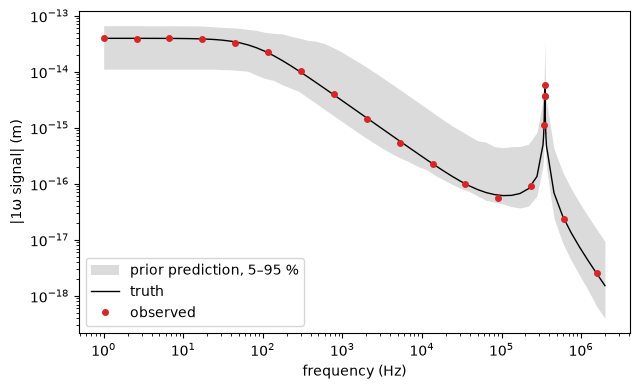

In [3]:
nominal = {"material": examples.licoo2(), "instrument": examples.afm_probe(), "junction": JunctionCard()}
axes = particles.names_of(nominal)                      # (card, field) of every uncertain value
z_true = np.array([0.6, 0.5, -0.6, 0.0, 0.0])           # eps_r, Y, D, beta_33, C_g, in prior widths
truth = particles.cards_at(nominal, axes, z_true)

f_cr = nominal["instrument"].contact_resonance_hz.value
readout = ExperimentCard(vac_peak_v=0.002, vdc_v=0.01, frequency_hz=1e3, temperature_k=300.0, normal_load_n=50e-9)
measured = FrequencySweep(readout=readout, frequencies_hz=sorted(
    np.concatenate([np.logspace(0, 6.2, 16), f_cr * np.array([0.98, 0.995, 1.0, 1.005])]))).steps()
curve = FrequencySweep(readout=readout, frequencies_hz=sorted(
    np.concatenate([np.logspace(0, 6.3, 60), f_cr * np.linspace(0.95, 1.05, 21)]))).steps()
f_measured, f_curve = [s.x for s in measured], [s.x for s in curve]

rng = np.random.default_rng(0)
observed = predict([truth], measured)[0] * np.exp(SIGMA * rng.standard_normal(len(measured)))
true_curve = predict([truth], curve)[0]


def draw_sets(nominal, n, rng):
    """n card sets drawn from the card distributions; draws outside the physical support are redrawn."""
    sets = []
    while len(sets) < n:
        try:
            sets.append({key: card.draw(rng) for key, card in nominal.items()})
        except ValueError:
            pass
    return sets


prior_band = np.nanpercentile(predict(draw_sets(nominal, 100, rng), curve), [5, 95], axis=0)

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.fill_between(f_curve, *prior_band, color="0.6", alpha=0.35, lw=0, label="prior prediction, 5–95 %")
ax.loglog(f_curve, true_curve, "k-", lw=1, label="truth")
ax.loglog(f_measured, observed, "o", color="C3", ms=4, label="observed")
ax.set_xlabel("frequency (Hz)")
ax.set_ylabel("|1ω signal| (m)")
ax.legend(loc="lower left")
fig.tight_layout()

## The particle filter

200 particles take in the observed points one by one. After every point the 5 / 50 / 95 % quantiles
of each parameter are recorded.

In [4]:
history = []
cards, z, w, axes, stats = particles.particle_filter(
    nominal, measured, observed, loglik, 200, rng, record=lambda k, z, w: history.append(particles.quantiles(z, w)))
print(f"resampled {stats['resamples']} times | move acceptance {stats['accepted'] / stats['proposed']:.2f} | "
      f"lowest effective number of particles {stats['min_ess']:.0f}")

resampled 8 times | move acceptance 0.25 | lowest effective number of particles 28


## 1. The updated predicted spectrum

The same prediction, now from 100 particles drawn by their weights: the posterior band. On the
spectrum it is as thin as the truth line, so the lower panel divides both bands by the truth.

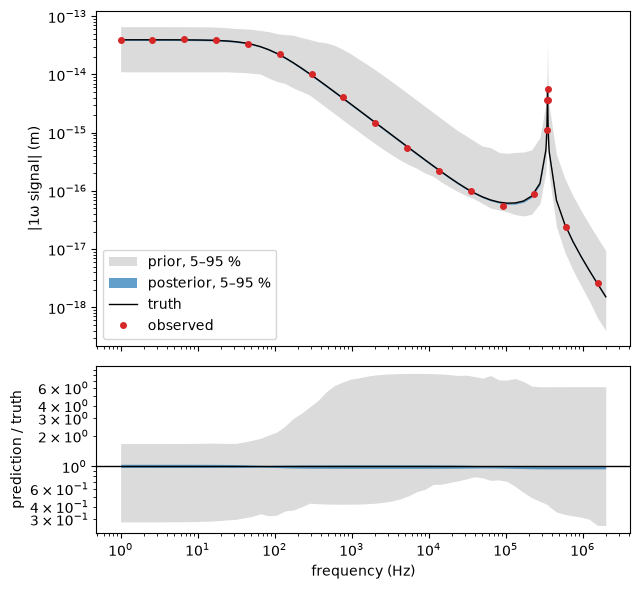

In [5]:
picked = rng.choice(len(cards), size=100, p=w)
posterior_band = np.nanpercentile(predict([cards[i] for i in picked], curve), [5, 95], axis=0)

fig, (top, bottom) = plt.subplots(2, 1, sharex=True, figsize=(6.5, 6), height_ratios=[2, 1])
for ax, scale in ((top, 1.0), (bottom, true_curve)):
    ax.fill_between(f_curve, prior_band[0] / scale, prior_band[1] / scale, color="0.6", alpha=0.35, lw=0,
                    label="prior, 5–95 %")
    ax.fill_between(f_curve, posterior_band[0] / scale, posterior_band[1] / scale, color="C0", alpha=0.7, lw=0,
                    label="posterior, 5–95 %")
top.loglog(f_curve, true_curve, "k-", lw=1, label="truth")
top.loglog(f_measured, observed, "o", color="C3", ms=4, label="observed")
bottom.axhline(1.0, color="k", lw=1)
bottom.set_yscale("log")
top.set_ylabel("|1ω signal| (m)")
bottom.set_ylabel("prediction / truth")
bottom.set_xlabel("frequency (Hz)")
top.legend(loc="lower left")
fig.tight_layout()

## 2. The parameter distributions: before and after

Grey: the prior, 2000 draws from the cards (draws outside the physical support dropped). Blue: the
posterior, the weighted particles. Black: the truth.

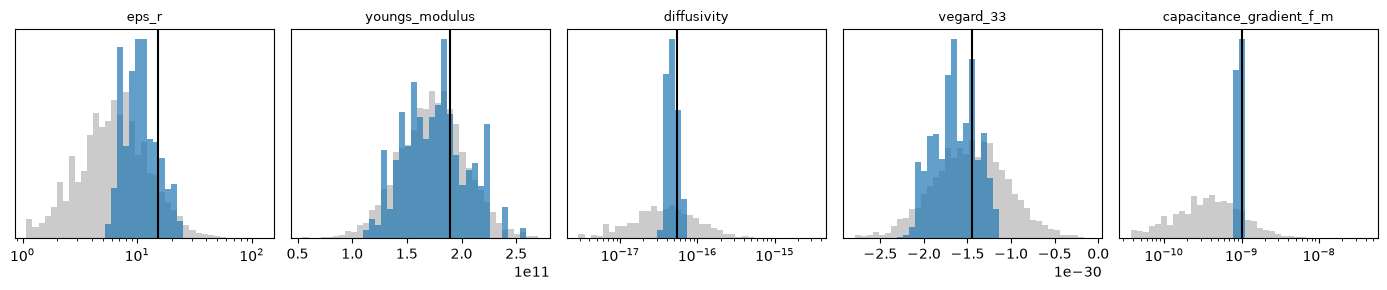

In [6]:
prior_sets = draw_sets(nominal, 2000, rng)
fig, panels = plt.subplots(1, len(axes), figsize=(14, 3))
for ax, (key, name) in zip(panels, axes):
    prior = nominal[key].uncertain()[name]
    before = np.array([s[key].uncertain()[name].value for s in prior_sets])
    after = np.array([c[key].uncertain()[name].value for c in cards])
    log = prior.dist == "lognormal"
    bins = np.geomspace(before.min(), before.max(), 40) if log else np.linspace(before.min(), before.max(), 40)
    ax.hist(before, bins=bins, density=True, color="0.6", alpha=0.5)
    ax.hist(after, bins=bins, weights=w, density=True, color="C0", alpha=0.7)
    ax.axvline(truth[key].uncertain()[name].value, color="k", lw=1.5)
    if log:
        ax.set_xscale("log")
    ax.set_yticks([])
    ax.set_title(name, fontsize=9)
fig.tight_layout()

## 3. How they changed during the filtering

The 5–95 % interval of each parameter after every observed point (band) and its median (line),
with the truth dashed. The points are in frequency order, so each parameter narrows where the
sweep reaches the feature that carries it.

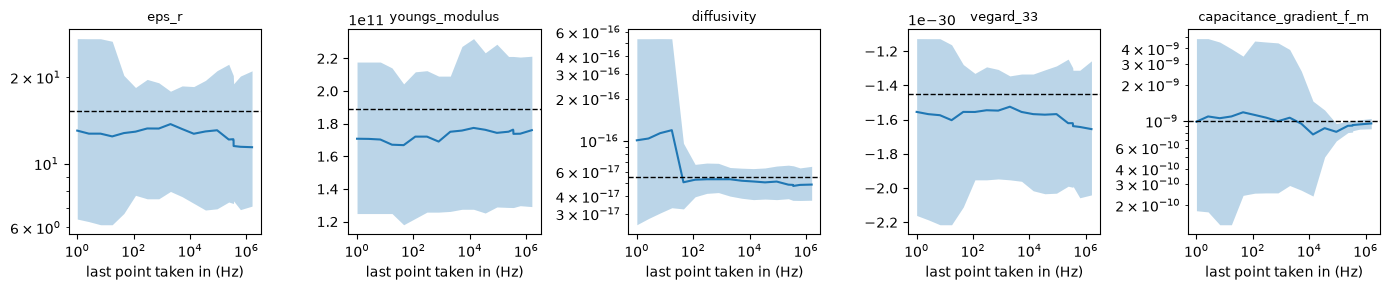

In [7]:
bands = np.array(history)                               # points x (5, 50, 95 %) x parameters
fig, panels = plt.subplots(1, len(axes), figsize=(14, 3))
for i, (ax, (key, name)) in enumerate(zip(panels, axes)):
    prior = nominal[key].uncertain()[name]
    low, mid, high = ([prior.at(v).value for v in bands[:, j, i]] for j in range(3))
    ax.fill_between(f_measured, low, high, color="C0", alpha=0.3, lw=0)
    ax.plot(f_measured, mid, "C0")
    ax.axhline(truth[key].uncertain()[name].value, color="k", ls="--", lw=1)
    ax.set_xscale("log")
    if prior.dist == "lognormal":
        ax.set_yscale("log")
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("last point taken in (Hz)")
fig.tight_layout()

## The updated cards

The posterior written back as ordinary cards, usable as the prior of the next experiment. A card holds
independent distributions only, so the strongest correlation it drops is printed beside it.

In [8]:
posterior, correlation = particles.updated_cards(nominal, axes, z, w)
for key, name in axes:
    before, after, true = (c[key].uncertain()[name].value for c in (nominal, posterior, truth))
    print(f"{name:26s} prior {before:9.3g}  ->  updated {after:9.3g}   (truth {true:9.3g})")
a, b = np.unravel_index(np.argmax(np.abs(correlation - np.eye(len(axes)))), correlation.shape)
print(f"strongest correlation the cards cannot hold: {axes[a][1]} / {axes[b][1]} = {correlation[a, b]:+.2f}")

eps_r                      prior        10  ->  updated        12   (truth      15.2)
youngs_modulus             prior  1.74e+11  ->  updated  1.76e+11   (truth  1.89e+11)
diffusivity                prior     1e-16  ->  updated  4.88e-17   (truth  5.49e-17)
vegard_33                  prior -1.45e-30  ->  updated -1.64e-30   (truth -1.45e-30)
capacitance_gradient_f_m   prior     1e-09  ->  updated  9.49e-10   (truth     1e-09)
strongest correlation the cards cannot hold: eps_r / vegard_33 = +0.99


## Reading the results

- **The prediction.** Before the data, the cards predict the sweep only to within a factor of
  about 3–7. After the data, the posterior prediction lies within a few percent of the truth at
  every frequency.
- **What the sweep determines:**
  - D and C_g become sharp and sit on the truth. D is set by the ionic roll-off, and C_g by the
    electrostatic term at the contact resonance.
  - εr and β₃₃ narrow only partly, and they move together. The sweep measures their combination
    (the Vegard plateau, ∝ c·√εr), not each one separately; the correlation printed above is close
    to 1.
  - Y stays at its prior, because the sweep barely depends on it.
- **During the filtering.** Each parameter narrows when the sweep reaches the feature that carries
  it: D at the roll-off near 10² Hz, and C_g at the resonance. εr and β₃₃ drift along their ridge.
- **The updated cards** can serve as the prior of the next experiment. They drop the εr–β₃₃
  correlation, which is printed beside them. A second experiment that measures D independently of
  εr, such as the pulse relaxation (τ = a²/4D), would cut that ridge.